# Hateful Memes - мультимодальная классификация мемов

**Задача.** По мему (картинка + текст на ней) предсказать, является ли он hateful (1) или нет (0).
Датасет - [The Hateful Memes Challenge](https://arxiv.org/abs/2005.04790) от Facebook AI.
Основная метрика - **AUROC**, дополнительно смотрю accuracy и F1 (так рекомендует README датасета).

**Что тут собрано.** Это один сводный ноутбук, куда я перенесла всё содержимое отдельных скриптов
проекта (`dataset.py`, `extract_image_features.py`, `extract_image_features_resnet.py`,
`zero_shot_clip_baseline.py`) и дописала недостающие этапы: текстовые признаки, обучение
классификаторов, сравнение, анализ ошибок и предсказания на тесте.

**Логика проекта.**

1. Не обучаю нейросеть с нуля - беру предобученные энкодеры и вытаскиваю из них эмбеддинги.
2. Картинки кодирую двумя способами (CLIP image encoder и ResNet50) - чтобы сравнить, какой лучше.
3. Текст кодирую CLIP text encoder + отдельно TF-IDF как чисто-NLP бейзлайн.
4. Поверх эмбеддингов учу обычный классификатор - это уже ML-часть.
5. Сравниваю всё с zero-shot CLIP, который вообще ничему не учится.

**Оглавление**

| № | Раздел | Что происходит |
|---|--------|----------------|
| 1 | Настройка | импорты, пути, стиль графиков |
| 2 | Загрузка данных | чтение jsonl в DataFrame |
| 3 | EDA | баланс классов, длины текстов, слова, примеры мемов |
| 4 | CV-признаки | CLIP image + ResNet50 эмбеддинги |
| 5 | NLP-признаки | CLIP text эмбеддинги + TF-IDF |
| 6 | Zero-shot бейзлайн | CLIP без обучения |
| 7 | Обучение классификаторов | сравнение наборов признаков |
| 8 | Подбор модели | гиперпараметры и разные алгоритмы |
| 9 | Оценка лучшей модели | ROC, матрица ошибок, порог |
| 10 | Анализ ошибок | на чём модель путается |
| 11 | Предсказания на test | сохранение submission |
| 12 | Выводы | итоговая таблица |

> **Как запускать.** Ячейки идут сверху вниз, каждая следующая опирается на предыдущие.
> Тяжёлые шаги (извлечение эмбеддингов) кэшируются в `data/features/` - если файл уже есть,
> ячейка просто его читает за секунду. Ядро - `venv` из этой же папки.

---
## 1. Настройка окружения

Проверяю, что все библиотеки на месте и вижу их версии. Если тут что-то падает - значит
выбрано не то ядро (нужен интерпретатор из `venv/` внутри папки проекта).

In [36]:
import json
import os
import sys
import time
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

import sklearn

print("python      ", sys.version.split()[0])
print("исполняемый ", sys.executable)
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("sklearn     ", sklearn.__version__)

# torch / open_clip нужны только для извлечения эмбеддингов.
# если эмбеддинги уже посчитаны и лежат в data/features, без них можно обойтись
try:
    import torch
    TORCH_OK = True
    print("torch       ", torch.__version__)
except ImportError:
    TORCH_OK = False
    print("torch        не установлен (ок, если эмбеддинги уже посчитаны)")

try:
    import open_clip
    OPEN_CLIP_OK = True
    print("open_clip   ", open_clip.__version__)
except Exception:
    OPEN_CLIP_OK = False
    print("open_clip    не установлен (ок, если эмбеддинги уже посчитаны)")

python       3.9.6
исполняемый  /Users/amina/Desktop/proj/venv_bofs/capstone project/venv/bin/python
numpy        2.0.2
pandas       2.3.3
sklearn      1.6.1
torch        2.8.0
open_clip    3.3.0


In [37]:
# пути. ноутбук лежит в корне проекта, рядом с папкой data/
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
IMG_DIR = DATA_DIR / "img"
FEATURES_DIR = DATA_DIR / "features"
FEATURES_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ["train", "dev", "test"]
RANDOM_STATE = 42

# устройство для торча: на маке mps обычно быстрее cpu, но не всегда стабилен,
# поэтому оставляю простой выбор cuda -> cpu, как в исходных скриптах
DEVICE = "cuda" if (TORCH_OK and torch.cuda.is_available()) else "cpu"

# на маке BLAS иногда поднимает ложные флаги переполнения в matmul,
# на результат это не влияет, но забивает вывод предупреждениями
np.seterr(all="ignore")

print("проект:", PROJECT_DIR)
print("device:", DEVICE)
print()

# проверяю что всё на месте, чтобы не ловить ошибку через 10 ячеек
checks = []
for name, p in [("img/", IMG_DIR), ("features/", FEATURES_DIR)]:
    checks.append((name, p.exists(), "папка"))
for s in SPLITS:
    checks.append((f"{s}.jsonl", (DATA_DIR / f"{s}.jsonl").exists(), "разметка"))

check_df = pd.DataFrame(checks, columns=["файл", "есть", "что это"])
check_df["есть"] = check_df["есть"].map({True: "да", False: "НЕТ"})
display(check_df)

n_images = len(list(IMG_DIR.glob("*.png"))) if IMG_DIR.exists() else 0
print(f"картинок в img/: {n_images}")

проект: /Users/amina/Desktop/proj/venv_bofs/capstone project
device: cpu



,файл,есть,что это
0,img/,да,папка
1,features/,да,папка
2,train.jsonl,да,разметка
3,dev.jsonl,да,разметка
4,test.jsonl,да,разметка


картинок в img/: 10000


In [38]:
# единый стиль графиков на весь ноутбук.
# палитра: синий = not hateful, оранжевый = hateful. цвета подобраны так,
# чтобы они различались и при цветовой слепоте, и в ч/б печати
C_BLUE   = "#2a78d6"   # класс 0 / основная серия
C_ORANGE = "#eb6834"   # класс 1 / вторая серия
C_AQUA   = "#1baf7a"   # третья серия
C_YELLOW = "#eda100"   # четвёртая серия
C_VIOLET = "#4a3aa7"   # пятая серия
C_GREY   = "#8a8a85"   # вспомогательное (случайный классификатор и т.п.)

CLASS_COLORS = {0: C_BLUE, 1: C_ORANGE}
CLASS_NAMES = {0: "not hateful", 1: "hateful"}
SERIES = [C_BLUE, C_ORANGE, C_AQUA, C_YELLOW, C_VIOLET]

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#d8d8d4",
    "axes.labelcolor": "#52514e",
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlecolor": "#0b0b0b",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#ececea",
    "grid.linewidth": 0.8,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "font.size": 10,
    "legend.frameon": False,
    "figure.dpi": 110,
})

def tidy(ax):
    """убираю верхнюю и правую рамку - они ничего не кодируют, только шумят"""
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    return ax

print("стиль применён")

стиль применён


---
## 2. Загрузка данных

Тут код из `dataset.py`: читаю `.jsonl` построчно и собираю в DataFrame с колонками
`id / text / label / img_path`. У `test.jsonl` поля `label` нет - это конкурсный сплит,
там `label` останется `NaN`.

In [39]:
def load_split(jsonl_path, images_root):
    """
    jsonl_path  - путь до train.jsonl / dev.jsonl / test.jsonl
    images_root - папка img/

    на выходе df с колонками: id, text, label, img_path
    (для test.jsonl label будет None, там его просто нет в разметке)
    """
    rows = []
    with open(jsonl_path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            item = json.loads(line)

            # путь к картинке уже лежит в поле "img" типа img/42953.png,
            # но собираю его сама через имя файла, вдруг структура где-то слетит
            img_path = Path(images_root) / Path(item["img"]).name

            rows.append({
                "id": item["id"],
                "text": item["text"],
                "label": item.get("label", None),
                "img_path": str(img_path),
            })
    return pd.DataFrame(rows)


dfs = {}
for split in SPLITS:
    dfs[split] = load_split(DATA_DIR / f"{split}.jsonl", IMG_DIR)

train_df, dev_df, test_df = dfs["train"], dfs["dev"], dfs["test"]

summary = pd.DataFrame({
    "сплит": SPLITS,
    "примеров": [len(dfs[s]) for s in SPLITS],
    "с лейблом": [int(dfs[s]["label"].notna().sum()) for s in SPLITS],
})
display(summary)
train_df.head()

,сплит,примеров,с лейблом
0,train,8500,8500
1,dev,500,500
2,test,1000,0


,id,text,label,img_path
0,42953,its their character not their color that matters,0,/Users/amina/Desktop/proj/venv_bofs/capstone p...
1,23058,don't be afraid to love again everyone is not ...,0,/Users/amina/Desktop/proj/venv_bofs/capstone p...
2,13894,putting bows on your pet,0,/Users/amina/Desktop/proj/venv_bofs/capstone p...
3,37408,i love everything and everybody! except for sq...,0,/Users/amina/Desktop/proj/venv_bofs/capstone p...
4,82403,"everybody loves chocolate chip cookies, even h...",0,/Users/amina/Desktop/proj/venv_bofs/capstone p...


In [40]:
# проверяю что все картинки реально лежат на диске - иначе извлечение фич
# тихо подсунет нулевые векторы и метрики поедут
for split in SPLITS:
    df = dfs[split]
    missing = (~df["img_path"].map(lambda p: Path(p).exists())).sum()
    print(f"{split:5s}: нет картинок для {missing} записей из {len(df)}")

# и что id не пересекаются между сплитами (утечка была бы фатальной)
ids = {s: set(dfs[s]["id"]) for s in SPLITS}
print()
print("пересечение train/dev:", len(ids["train"] & ids["dev"]))
print("пересечение train/test:", len(ids["train"] & ids["test"]))
print("пересечение dev/test:", len(ids["dev"] & ids["test"]))

train: нет картинок для 0 записей из 8500
dev  : нет картинок для 0 записей из 500
test : нет картинок для 0 записей из 1000

пересечение train/dev: 0
пересечение train/test: 0
пересечение dev/test: 0


---
## 3. Разведочный анализ (EDA)

Смотрю, с чем вообще имею дело: насколько несбалансированы классы, какие тексты по длине,
какие слова характерны для каждого класса и как выглядят сами мемы.

In [41]:
# баланс классов в train и dev
bal = pd.DataFrame({
    "train": train_df["label"].value_counts().sort_index(),
    "dev": dev_df["label"].value_counts().sort_index(),
})
bal.index = [CLASS_NAMES[int(i)] for i in bal.index]
bal.loc["всего"] = bal.sum()
display(bal)

share_hateful = train_df["label"].mean()
print(f"доля hateful в train: {share_hateful:.1%}")
print(f"доля hateful в dev:   {dev_df['label'].mean():.1%}")
print()
print("важный момент: train перекошен в сторону not hateful, а dev сбалансирован 50/50.")
print("значит accuracy тупого 'всегда not hateful' предсказания на dev =",
      f"{1 - dev_df['label'].mean():.1%} - вот с чем надо сравнивать accuracy.")
print("и ещё: модель, обученная на перекошенном train, будет по умолчанию")
print("недооценивать класс hateful на сбалансированном dev - это всплывёт при выборе порога")

,train,dev
not hateful,5450,250
hateful,3050,250
всего,8500,500


доля hateful в train: 35.9%
доля hateful в dev:   50.0%

важный момент: train перекошен в сторону not hateful, а dev сбалансирован 50/50.
значит accuracy тупого 'всегда not hateful' предсказания на dev = 50.0% - вот с чем надо сравнивать accuracy.
и ещё: модель, обученная на перекошенном train, будет по умолчанию
недооценивать класс hateful на сбалансированном dev - это всплывёт при выборе порога


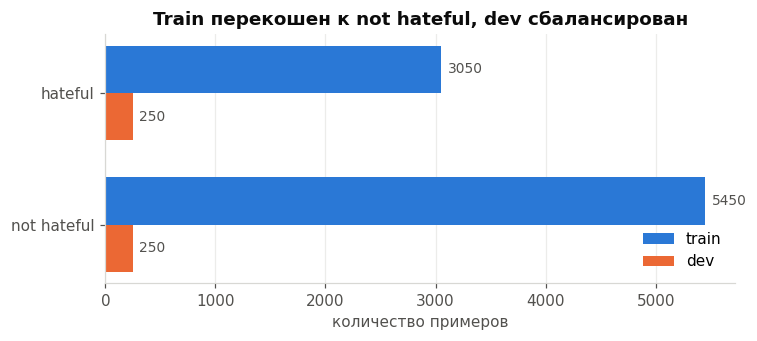

In [42]:
# один график: сколько примеров каждого класса в train и dev.
# горизонтальные бары, потому что подписи классов - слова, а не числа
fig, ax = plt.subplots(figsize=(7, 3.2))

counts = pd.DataFrame({
    "train": train_df["label"].value_counts().sort_index(),
    "dev": dev_df["label"].value_counts().sort_index(),
})
y = np.arange(len(counts))
h = 0.36

ax.barh(y + h / 2, counts["train"], height=h, color=C_BLUE, label="train")
ax.barh(y - h / 2, counts["dev"], height=h, color=C_ORANGE, label="dev")

for yi, v in zip(y + h / 2, counts["train"]):
    ax.text(v + 60, yi, f"{int(v)}", va="center", fontsize=9, color="#52514e")
for yi, v in zip(y - h / 2, counts["dev"]):
    ax.text(v + 60, yi, f"{int(v)}", va="center", fontsize=9, color="#52514e")

ax.set_yticks(y)
ax.set_yticklabels([CLASS_NAMES[int(i)] for i in counts.index])
ax.set_xlabel("количество примеров")
ax.set_title("Train перекошен к not hateful, dev сбалансирован")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
tidy(ax)
plt.tight_layout()
plt.show()

label               0       1
n_words count  5450.0  3050.0
        mean     11.2    12.8
        std       6.6     7.3
        min       1.0     1.0
        25%       7.0     8.0
        50%      10.0    11.0
        75%      14.0    17.0
        max      69.0    70.0
n_chars count  5450.0  3050.0
        mean     58.5    68.5
        std      35.1    39.5
        min       4.0     4.0
        25%      35.0    40.0
        50%      51.0    61.0
        75%      72.0    88.0
        max     433.0   406.0

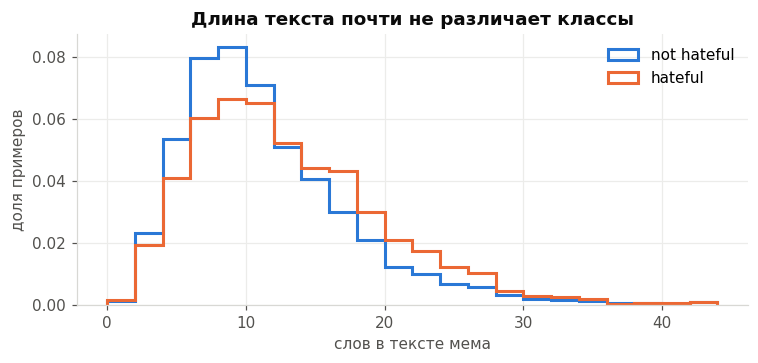

вывод: распределения почти совпадают, значит длина текста сама по себе - слабый признак


In [43]:
# длина текста в словах - вдруг hateful мемы систематически длиннее/короче
for df in (train_df, dev_df, test_df):
    df["n_words"] = df["text"].str.split().str.len()
    df["n_chars"] = df["text"].str.len()

display(train_df.groupby("label")[["n_words", "n_chars"]].describe().round(1).T)

fig, ax = plt.subplots(figsize=(7, 3.4))
bins = np.arange(0, 46, 2)
for lab in [0, 1]:
    ax.hist(train_df.loc[train_df["label"] == lab, "n_words"], bins=bins,
            histtype="step", linewidth=2, color=CLASS_COLORS[lab],
            density=True, label=CLASS_NAMES[lab])
ax.set_xlabel("слов в тексте мема")
ax.set_ylabel("доля примеров")
ax.set_title("Длина текста почти не различает классы")
ax.legend()
tidy(ax)
plt.tight_layout()
plt.show()

print("вывод: распределения почти совпадают, значит длина текста сама по себе - слабый признак")

In [44]:
# какие слова чаще встречаются в hateful текстах.
# считаю простую метрику: доля документов класса 1 среди документов со словом
STOPWORDS = set("""
a an the and or but if then than that this these those of in on at to for from with
without by as is are was were be been being am do does did doing have has had having
i you he she it we they me him her them my your his its our their not no so too very
can will just dont don't im i'm its it's what when where who whom which how why
""".split())

def word_stats(df, min_count=25):
    docs_with_word = Counter()
    docs_with_word_hateful = Counter()
    for text, lab in zip(df["text"], df["label"]):
        words = {w.strip(".,!?:;\"'()") for w in str(text).lower().split()}
        words = {w for w in words if len(w) > 2 and w not in STOPWORDS and w.isalpha()}
        for w in words:
            docs_with_word[w] += 1
            if lab == 1:
                docs_with_word_hateful[w] += 1
    rows = []
    for w, n in docs_with_word.items():
        if n >= min_count:
            rows.append((w, n, docs_with_word_hateful[w] / n))
    return pd.DataFrame(rows, columns=["слово", "документов", "доля_hateful"])

ws = word_stats(train_df).sort_values("доля_hateful", ascending=False)
base = train_df["label"].mean()

print(f"базовая доля hateful = {base:.2f}\n")
print("--- слова, максимально сдвинутые в сторону hateful ---")
display(ws.head(15).reset_index(drop=True))
print("--- слова, максимально сдвинутые в сторону not hateful ---")
display(ws.tail(15).iloc[::-1].reset_index(drop=True))

базовая доля hateful = 0.36

--- слова, максимально сдвинутые в сторону hateful ---


,слово,документов,доля_hateful
0,jews,99,0.888889
1,gays,26,0.807692
2,transgender,30,0.800000
3,retarded,27,0.777778
4,islam,89,0.775281
5,muslims,173,0.716763
6,jew,42,0.714286
7,tranny,87,0.701149
8,jewish,64,0.687500
9,christians,35,0.685714


--- слова, максимально сдвинутые в сторону not hateful ---


,слово,документов,доля_hateful
0,hillary,27,0.037037
1,strip,48,0.041667
2,club,51,0.058824
3,meanwhile,50,0.060000
4,memes,27,0.074074
5,omar,37,0.108108
6,isis,67,0.119403
7,guns,32,0.125000
8,feel,38,0.131579
9,beautiful,29,0.137931


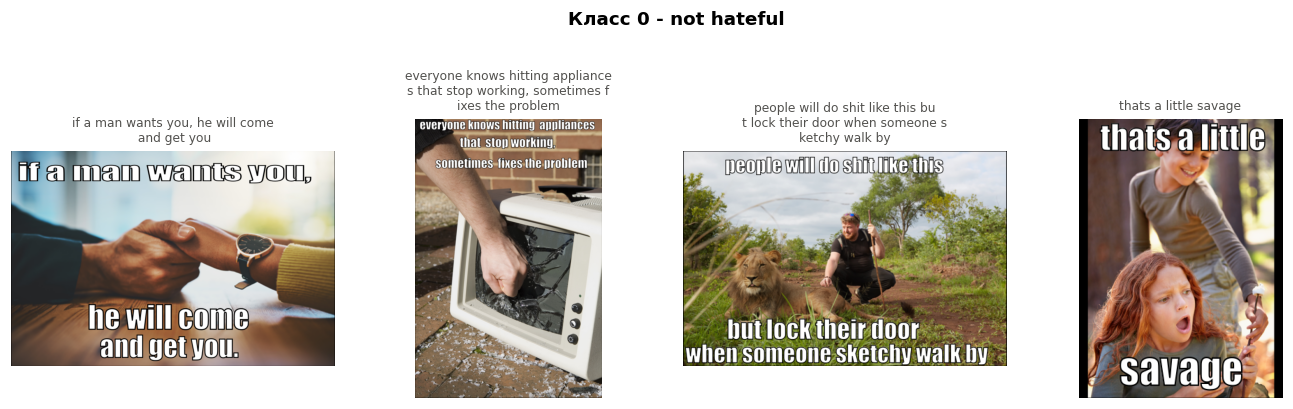

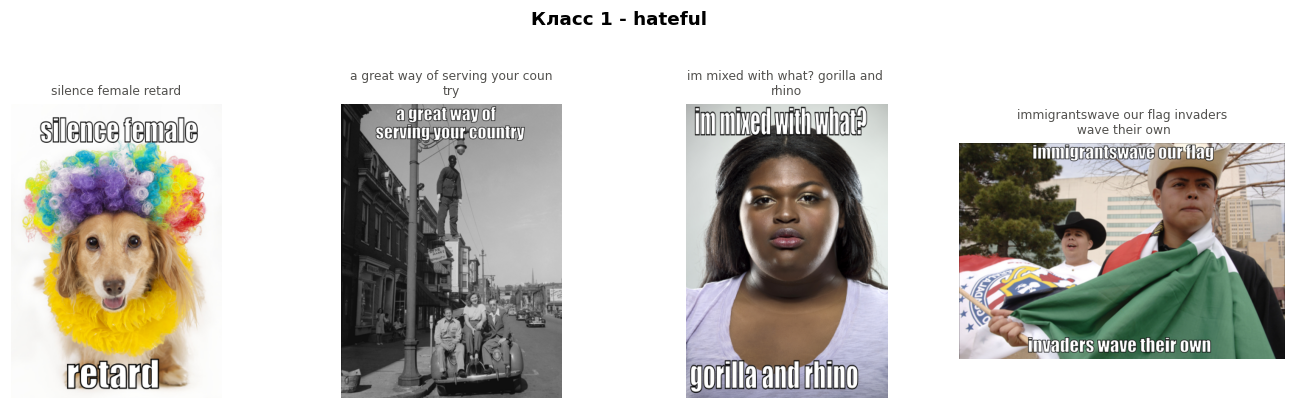

видно главную сложность: смысл рождается из пары картинка+текст,
по отдельности они часто выглядят безобидно


In [45]:
# теперь на сами мемы посмотрю глазами - без этого непонятно, почему задача сложная
from PIL import Image

def show_examples(df, label, n=4, title=""):
    sample = df[df["label"] == label].sample(n, random_state=RANDOM_STATE)
    fig, axes = plt.subplots(1, n, figsize=(3.1 * n, 3.6))
    for ax, (_, row) in zip(np.atleast_1d(axes), sample.iterrows()):
        try:
            ax.imshow(Image.open(row["img_path"]).convert("RGB"))
        except Exception as e:
            ax.text(0.5, 0.5, f"нет картинки\n{e}", ha="center", va="center")
        ax.set_axis_off()
        txt = row["text"]
        ax.set_title("\n".join([txt[i:i + 32] for i in range(0, min(len(txt), 96), 32)]),
                     fontsize=8, color="#52514e", fontweight="normal")
    fig.suptitle(title, fontsize=12, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()

show_examples(train_df, 0, 4, "Класс 0 - not hateful")
show_examples(train_df, 1, 4, "Класс 1 - hateful")
print("видно главную сложность: смысл рождается из пары картинка+текст,")
print("по отдельности они часто выглядят безобидно")

---
## 4. CV-часть: эмбеддинги картинок

Здесь код из `extract_image_features.py` и `extract_image_features_resnet.py`.

Беру два разных энкодера, чтобы потом честно сравнить:

| Энкодер | Размерность | Чему учился | Ожидание |
|---|---|---|---|
| CLIP ViT-B/32 image | 512 | сопоставлять картинку и её описание | «смысловой», для мемов должен зайти лучше |
| ResNet50 (ImageNet) | 2048 | различать 1000 объектов | видит объекты, но не связь с текстом |

Оба вектора L2-нормализую - так эмбеддинги CLIP принято использовать, и масштаб
двух наборов признаков становится сопоставимым.

**Важно про время.** Прогон 10 000 картинок через сеть на CPU - это десятки минут.
Поэтому ячейки ниже сначала ищут готовый `.npy` в `data/features/` и считают заново,
только если файла нет.

In [46]:
# ---- извлечение CLIP image эмбеддингов (используется, только если кэша нет) ----
CLIP_MODEL_NAME = "ViT-B-32"
CLIP_PRETRAINED = "openai"
BATCH_SIZE = 32

_clip_cache = {}

def load_clip():
    """загружаю CLIP один раз и держу в памяти - повторная загрузка долгая"""
    if "model" not in _clip_cache:
        model, _, preprocess = open_clip.create_model_and_transforms(
            CLIP_MODEL_NAME, pretrained=CLIP_PRETRAINED
        )
        model.eval().to(DEVICE)
        _clip_cache["model"] = model
        _clip_cache["preprocess"] = preprocess
        _clip_cache["tokenizer"] = open_clip.get_tokenizer(CLIP_MODEL_NAME)
    return _clip_cache["model"], _clip_cache["preprocess"], _clip_cache["tokenizer"]


def _batch_images(paths, preprocess):
    images = []
    for img_path in paths:
        try:
            img = Image.open(img_path).convert("RGB")
            images.append(preprocess(img))
        except Exception as e:
            # битую картинку не роняю весь процесс - кладу нулевой вектор
            print(f"не смогла открыть {img_path}: {e}")
            images.append(torch.zeros(3, 224, 224))
    return torch.stack(images).to(DEVICE)


def extract_clip_image(df):
    model, preprocess, _ = load_clip()
    out = []
    t0 = time.time()
    for start in range(0, len(df), BATCH_SIZE):
        batch = df.iloc[start:start + BATCH_SIZE]
        tensor = _batch_images(batch["img_path"], preprocess)
        with torch.no_grad():
            feats = model.encode_image(tensor)
            feats = feats / feats.norm(dim=-1, keepdim=True)
        out.append(feats.cpu().numpy())
        if start % (BATCH_SIZE * 20) == 0:
            print(f"  {start}/{len(df)}  ({time.time() - t0:.0f} с)", end="\r")
    return np.concatenate(out, axis=0).astype(np.float32)


def get_clip_image_embeddings(split):
    """читаю кэш, если он есть; иначе считаю и сохраняю"""
    path = FEATURES_DIR / f"{split}_image_embeddings.npy"
    if path.exists():
        emb = np.load(path)
        print(f"{split:5s}: CLIP image эмбеддинги взяты из кэша {emb.shape}")
        return emb
    print(f"{split:5s}: кэша нет, считаю CLIP image эмбеддинги (это долго)...")
    emb = extract_clip_image(dfs[split])
    np.save(path, emb)
    dfs[split][["id", "text", "label"]].to_csv(FEATURES_DIR / f"{split}_meta.csv", index=False)
    print(f"{split:5s}: посчитала и сохранила {emb.shape}")
    return emb


img_clip = {s: get_clip_image_embeddings(s) for s in SPLITS}

train: CLIP image эмбеддинги взяты из кэша (8500, 512)
dev  : CLIP image эмбеддинги взяты из кэша (500, 512)
test : CLIP image эмбеддинги взяты из кэша (1000, 512)


In [47]:
# ---- ResNet50 эмбеддинги ----
def load_resnet():
    from torchvision import models
    import torch.nn as nn
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    model.fc = nn.Identity()   # отрезаю классификационный слой, остаётся вектор 2048
    model.eval().to(DEVICE)
    return model


def resnet_preprocess():
    from torchvision import transforms
    # именно эти значения нормализации - те, на которых resnet50 учился на ImageNet
    return transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])


def extract_resnet(df):
    model = load_resnet()
    preprocess = resnet_preprocess()
    out = []
    for start in range(0, len(df), BATCH_SIZE):
        batch = df.iloc[start:start + BATCH_SIZE]
        tensor = _batch_images(batch["img_path"], preprocess)
        with torch.no_grad():
            feats = model(tensor)
            feats = feats / feats.norm(dim=-1, keepdim=True)
        out.append(feats.cpu().numpy())
        if start % (BATCH_SIZE * 20) == 0:
            print(f"  {start}/{len(df)}", end="\r")
    return np.concatenate(out, axis=0).astype(np.float32)


def get_resnet_embeddings(split):
    path = FEATURES_DIR / f"{split}_resnet_embeddings.npy"
    if path.exists():
        emb = np.load(path)
        print(f"{split:5s}: ResNet эмбеддинги взяты из кэша {emb.shape}")
        return emb
    print(f"{split:5s}: кэша нет, считаю ResNet эмбеддинги (это долго)...")
    emb = extract_resnet(dfs[split])
    np.save(path, emb)
    print(f"{split:5s}: посчитала и сохранила {emb.shape}")
    return emb


img_resnet = {s: get_resnet_embeddings(s) for s in SPLITS}

train: ResNet эмбеддинги взяты из кэша (8500, 2048)
dev  : ResNet эмбеддинги взяты из кэша (500, 2048)
test : ResNet эмбеддинги взяты из кэша (1000, 2048)


CLIP    shape=(500, 512)  норма: min=1.000 max=1.000
ResNet  shape=(500, 2048)  норма: min=1.000 max=1.000


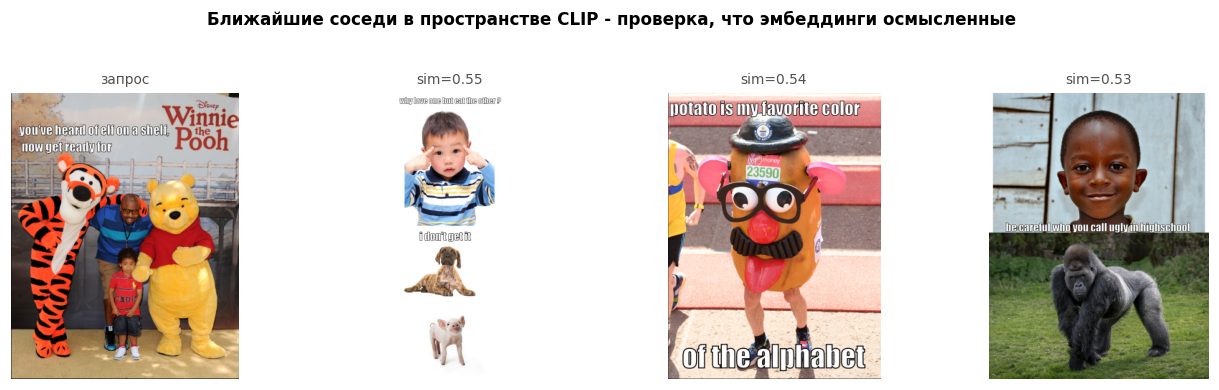

In [48]:
# быстрая проверка вменяемости эмбеддингов: нормы должны быть 1,
# и похожие картинки должны быть близки друг к другу
for name, emb in [("CLIP", img_clip["dev"]), ("ResNet", img_resnet["dev"])]:
    norms = np.linalg.norm(emb, axis=1)
    print(f"{name:7s} shape={emb.shape}  норма: min={norms.min():.3f} max={norms.max():.3f}")

# нахожу для случайного мема 3 ближайших по CLIP и смотрю, похожи ли они
q = 7
sims = img_clip["dev"] @ img_clip["dev"][q]
nearest = np.argsort(-sims)[:4]   # первый - сам запрос

fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, idx in zip(axes, nearest):
    row = dev_df.iloc[idx]
    ax.imshow(Image.open(row["img_path"]).convert("RGB"))
    ax.set_axis_off()
    tag = "запрос" if idx == q else f"sim={sims[idx]:.2f}"
    ax.set_title(tag, fontsize=9, color="#52514e", fontweight="normal")
fig.suptitle("Ближайшие соседи в пространстве CLIP - проверка, что эмбеддинги осмысленные",
             fontsize=11, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

---
## 5. NLP-часть: признаки из текста

Двумя способами:

1. **CLIP text encoder** - те же 512 измерений, что и у картинок, и **в том же пространстве**.
   Это ключевой момент: можно посчитать косинусную близость между картинкой и её подписью
   и использовать её как отдельный признак «насколько текст соответствует картинке».
2. **TF-IDF** - классический мешок слов. Нужен как честный чисто-текстовый бейзлайн:
   если он покажет много, значит задача решается словами и картинка не так уж важна.

In [49]:
def extract_clip_text(texts):
    model, _, tokenizer = load_clip()
    out = []
    for start in range(0, len(texts), 256):
        chunk = list(texts[start:start + 256])
        tokens = tokenizer(chunk).to(DEVICE)
        with torch.no_grad():
            feats = model.encode_text(tokens)
            feats = feats / feats.norm(dim=-1, keepdim=True)
        out.append(feats.cpu().numpy())
    return np.concatenate(out, axis=0).astype(np.float32)


def get_clip_text_embeddings(split):
    path = FEATURES_DIR / f"{split}_text_embeddings.npy"
    if path.exists():
        emb = np.load(path)
        print(f"{split:5s}: CLIP text эмбеддинги из кэша {emb.shape}")
        return emb
    print(f"{split:5s}: считаю CLIP text эмбеддинги (быстро, текст лёгкий)...")
    emb = extract_clip_text(dfs[split]["text"].tolist())
    np.save(path, emb)
    print(f"{split:5s}: сохранила {emb.shape}")
    return emb


txt_clip = {s: get_clip_text_embeddings(s) for s in SPLITS}

train: CLIP text эмбеддинги из кэша (8500, 512)
dev  : CLIP text эмбеддинги из кэша (500, 512)
test : CLIP text эмбеддинги из кэша (1000, 512)


         mean     50%     std
label                        
0      0.2898  0.2942  0.0493
1      0.2923  0.2986  0.0515


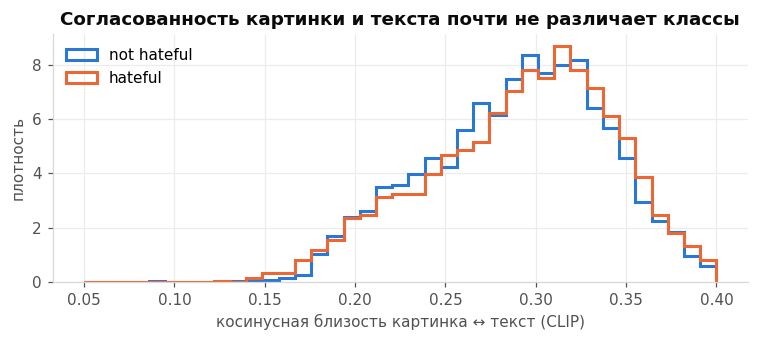

In [50]:
# косинус между картинкой и её собственным текстом.
# гипотеза: у hateful мемов текст и картинка сочетаются "неестественно",
# то есть близость может отличаться от обычных мемов
for split in SPLITS:
    dfs[split]["img_text_sim"] = (img_clip[split] * txt_clip[split]).sum(axis=1)

print(train_df.groupby("label")["img_text_sim"].describe()[["mean", "50%", "std"]].round(4))

fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.linspace(0.05, 0.40, 40)
for lab in [0, 1]:
    ax.hist(train_df.loc[train_df["label"] == lab, "img_text_sim"], bins=bins,
            histtype="step", linewidth=2, color=CLASS_COLORS[lab],
            density=True, label=CLASS_NAMES[lab])
ax.set_xlabel("косинусная близость картинка ↔ текст (CLIP)")
ax.set_ylabel("плотность")
ax.set_title("Согласованность картинки и текста почти не различает классы")
ax.legend()
tidy(ax)
plt.tight_layout()
plt.show()

In [51]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    ngram_range=(1, 2),   # униграммы + биграммы, устойчивые словосочетания важны
    min_df=2,             # слова-одиночки выкидываю, это шум
    sublinear_tf=True,
    strip_accents="unicode",
)
X_tfidf_train = tfidf.fit_transform(train_df["text"])
X_tfidf_dev = tfidf.transform(dev_df["text"])
X_tfidf_test = tfidf.transform(test_df["text"])

print("TF-IDF матрица train:", X_tfidf_train.shape,
      f"(заполнено {X_tfidf_train.nnz / np.prod(X_tfidf_train.shape):.4%})")

TF-IDF матрица train: (8500, 17989) (заполнено 0.0911%)


---
## 6. Zero-shot бейзлайн на CLIP

Код из `zero_shot_clip_baseline.py`. Никакого обучения: описываю оба класса словами,
кодирую эти описания CLIP-ом и смотрю, к какому описанию картинка ближе.

Смысл бейзлайна - понять, с чем сравнивать обученную модель. Если обученный классификатор
заметно лучше zero-shot, значит обучение действительно что-то даёт.

Картинки заново прогонять не нужно: сохранённые image-эмбеддинги уже нормализованы,
так что весь zero-shot сводится к одному матричному умножению.

In [52]:
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score

# от формулировки промптов качество реально зависит, поэтому пробую несколько наборов
PROMPT_SETS = {
    "базовый": ("a normal meme, not hateful",
                "a hateful meme, offensive or discriminatory"),
    "короткий": ("a photo", "a hateful photo"),
    "развёрнутый": ("a harmless funny internet meme",
                    "an internet meme that attacks a group of people by race, religion or gender"),
}

def zero_shot_probs(image_emb, prompts):
    model, _, tokenizer = load_clip()
    tokens = tokenizer(list(prompts)).to(DEVICE)
    with torch.no_grad():
        tfeat = model.encode_text(tokens)
        tfeat = tfeat / tfeat.norm(dim=-1, keepdim=True)
    tfeat = tfeat.cpu().numpy()
    # температура 100 - стандартное значение из статьи CLIP
    logits = 100.0 * image_emb @ tfeat.T
    e = np.exp(logits - logits.max(axis=1, keepdims=True))
    probs = e / e.sum(axis=1, keepdims=True)
    return probs[:, 1]            # вероятность класса "hateful"


y_dev = dev_df["label"].astype(int).values

zs_rows = []
zs_probs = {}
for name, prompts in PROMPT_SETS.items():
    p = zero_shot_probs(img_clip["dev"], prompts)
    zs_probs[name] = p
    zs_rows.append({
        "промпты": name,
        "accuracy": accuracy_score(y_dev, (p >= 0.5).astype(int)),
        "roc_auc": roc_auc_score(y_dev, p),
        "f1": f1_score(y_dev, (p >= 0.5).astype(int), zero_division=0),
    })

zs_df = pd.DataFrame(zs_rows).set_index("промпты").round(3)
display(zs_df)

best_prompt = zs_df["roc_auc"].idxmax()
ZERO_SHOT_AUC = zs_df.loc[best_prompt, "roc_auc"]
zero_shot_dev_probs = zs_probs[best_prompt]
print(f"лучший набор промптов: «{best_prompt}», AUROC = {ZERO_SHOT_AUC:.3f}")
print()
print("напоминание: AUROC 0.5 - это монетка, 1.0 - идеал.")
print(f"разброс между формулировками промптов: "
      f"{zs_df['roc_auc'].min():.3f} .. {zs_df['roc_auc'].max():.3f} -")
print("то есть от одной только формулировки качество гуляет заметно,")
print("что само по себе говорит о ненадёжности zero-shot на этой задаче")

,accuracy,roc_auc,f1
промпты,,,
базовый,0.506,0.523,0.612
короткий,0.522,0.576,0.638
развёрнутый,0.580,0.601,0.553


лучший набор промптов: «развёрнутый», AUROC = 0.601

напоминание: AUROC 0.5 - это монетка, 1.0 - идеал.
разброс между формулировками промптов: 0.523 .. 0.601 -
то есть от одной только формулировки качество гуляет заметно,
что само по себе говорит о ненадёжности zero-shot на этой задаче


---
## 7. ML-часть: обучаю классификаторы поверх эмбеддингов

Схема простая: эмбеддинги - это признаки, сверху ставлю обычный классификатор из sklearn.
Обучаю на `train`, качество меряю на `dev`. Тест не трогаю до самого конца.

Сравниваю наборы признаков, чтобы ответить на главные вопросы проекта:

- что сильнее - текст или картинка;
- какой image-энкодер лучше, CLIP или ResNet;
- даёт ли объединение модальностей прирост над лучшей одиночной.

Для объединения кроме простой конкатенации пробую добавить **поэлементное произведение**
image- и text-эмбеддингов: это грубая модель взаимодействия модальностей, которая
конкатенации недоступна (линейная модель на конкатенации не умеет «умножать» признаки).

In [53]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

y_train = train_df["label"].astype(int).values
y_dev = dev_df["label"].astype(int).values


def build_features(split, blocks):
    """собираю матрицу признаков из названных блоков"""
    parts = []
    for b in blocks:
        if b == "img_clip":
            parts.append(img_clip[split])
        elif b == "img_resnet":
            parts.append(img_resnet[split])
        elif b == "txt_clip":
            parts.append(txt_clip[split])
        elif b == "product":
            # поэлементное произведение картинки и текста в общем пространстве CLIP
            parts.append(img_clip[split] * txt_clip[split])
        elif b == "sim":
            parts.append(dfs[split][["img_text_sim"]].values.astype(np.float32))
        else:
            raise ValueError(f"неизвестный блок признаков: {b}")
    return np.hstack(parts)


def evaluate(y_true, probs, threshold=0.5):
    preds = (probs >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, preds),
        "roc_auc": roc_auc_score(y_true, probs),
        "f1": f1_score(y_true, preds, zero_division=0),
    }


RESULTS = []   # сюда складываю все прогоны, в конце соберу в таблицу

def run_experiment(name, blocks, clf=None, note=""):
    Xtr = build_features("train", blocks)
    Xdv = build_features("dev", blocks)
    if clf is None:
        clf = LogisticRegression(max_iter=3000, C=1.0, random_state=RANDOM_STATE)
    pipe = make_pipeline(StandardScaler(), clf)
    t0 = time.time()
    pipe.fit(Xtr, y_train)
    probs = pipe.predict_proba(Xdv)[:, 1]
    res = evaluate(y_dev, probs)
    res.update({"эксперимент": name, "признаков": Xtr.shape[1],
                "сек": round(time.time() - t0, 1), "note": note, "blocks": blocks})
    RESULTS.append(res)
    print(f"{name:34s} AUROC={res['roc_auc']:.3f}  acc={res['accuracy']:.3f}  "
          f"F1={res['f1']:.3f}  ({res['сек']} с)")
    return pipe, probs

In [54]:
# сначала бейзлайны, с которыми всё сравнивается
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="prior", random_state=RANDOM_STATE).fit(
    np.zeros((len(y_train), 1)), y_train)
dummy_probs = dummy.predict_proba(np.zeros((len(y_dev), 1)))[:, 1]
res = evaluate(y_dev, dummy_probs)
res.update({"эксперимент": "0. всегда мажоритарный класс", "признаков": 0,
            "сек": 0.0, "note": "нижняя граница", "blocks": None})
RESULTS.append(res)
print(f"{'всегда not hateful':34s} AUROC={res['roc_auc']:.3f}  acc={res['accuracy']:.3f}")

res = evaluate(y_dev, zero_shot_dev_probs)
res.update({"эксперимент": "0. zero-shot CLIP (без обучения)", "признаков": 0,
            "сек": 0.0, "note": f"промпты: {best_prompt}", "blocks": None})
RESULTS.append(res)
print(f"{'zero-shot CLIP':34s} AUROC={res['roc_auc']:.3f}  acc={res['accuracy']:.3f}")

# чисто текстовый бейзлайн на TF-IDF (без эмбеддингов вообще)
tfidf_clf = LogisticRegression(max_iter=3000, C=5.0, random_state=RANDOM_STATE)
tfidf_clf.fit(X_tfidf_train, y_train)
tfidf_probs = tfidf_clf.predict_proba(X_tfidf_dev)[:, 1]
res = evaluate(y_dev, tfidf_probs)
res.update({"эксперимент": "1. TF-IDF текст + LogReg",
            "признаков": X_tfidf_train.shape[1], "сек": 0.0,
            "note": "чистый NLP", "blocks": None})
RESULTS.append(res)
print(f"{'TF-IDF + LogReg':34s} AUROC={res['roc_auc']:.3f}  acc={res['accuracy']:.3f}  F1={res['f1']:.3f}")

всегда not hateful                 AUROC=0.500  acc=0.500
zero-shot CLIP                     AUROC=0.601  acc=0.580
TF-IDF + LogReg                    AUROC=0.570  acc=0.518  F1=0.254


In [55]:
# теперь основная серия: одна и та же LogReg на разных наборах эмбеддингов.
# всё, что меняется между строчками, - это признаки, так что сравнение честное
_, p_txt      = run_experiment("2. только текст (CLIP)",        ["txt_clip"])
_, p_imgclip  = run_experiment("3. только картинка (CLIP)",     ["img_clip"])
_, p_imgres   = run_experiment("4. только картинка (ResNet50)", ["img_resnet"])
_, p_fuse     = run_experiment("5. CLIP картинка + текст",      ["img_clip", "txt_clip"])
_, p_fuse_res = run_experiment("6. ResNet картинка + текст",    ["img_resnet", "txt_clip"])
_, p_fuse_pr  = run_experiment("7. CLIP img + txt + произведение",
                               ["img_clip", "txt_clip", "product", "sim"])
_, p_all      = run_experiment("8. CLIP + ResNet + текст",
                               ["img_clip", "img_resnet", "txt_clip"])

2. только текст (CLIP)             AUROC=0.627  acc=0.552  F1=0.349  (0.3 с)
3. только картинка (CLIP)          AUROC=0.635  acc=0.578  F1=0.460  (0.2 с)
4. только картинка (ResNet50)      AUROC=0.482  acc=0.484  F1=0.371  (0.6 с)
5. CLIP картинка + текст           AUROC=0.664  acc=0.588  F1=0.458  (0.5 с)
6. ResNet картинка + текст         AUROC=0.571  acc=0.548  F1=0.449  (1.4 с)
7. CLIP img + txt + произведение   AUROC=0.662  acc=0.576  F1=0.462  (0.6 с)
8. CLIP + ResNet + текст           AUROC=0.570  acc=0.538  F1=0.464  (2.1 с)


In [56]:
res_df = (pd.DataFrame(RESULTS)
          .set_index("эксперимент")[["roc_auc", "accuracy", "f1", "признаков", "сек", "note"]]
          .round(3))
display(res_df.sort_values("roc_auc", ascending=False))

print("что видно:")
print(" - ResNet-признаки работают хуже CLIP-овых, местами даже хуже монетки;")
print(" - TF-IDF по тексту почти ничего не даёт: дело не в отдельных словах;")
print(" - объединение картинки и текста лучше каждой модальности по отдельности.")

,roc_auc,accuracy,f1,признаков,сек,note
эксперимент,,,,,,
5. CLIP картинка + текст,0.664,0.588,0.458,1024,0.5,
7. CLIP img + txt + произведение,0.662,0.576,0.462,1537,0.6,
3. только картинка (CLIP),0.635,0.578,0.460,512,0.2,
2. только текст (CLIP),0.627,0.552,0.349,512,0.3,
0. zero-shot CLIP (без обучения),0.601,0.580,0.553,0,0.0,промпты: развёрнутый
6. ResNet картинка + текст,0.571,0.548,0.449,2560,1.4,
1. TF-IDF текст + LogReg,0.570,0.518,0.254,17989,0.0,чистый NLP
8. CLIP + ResNet + текст,0.570,0.538,0.464,3072,2.1,
0. всегда мажоритарный класс,0.500,0.500,0.000,0,0.0,нижняя граница


что видно:
 - ResNet-признаки работают хуже CLIP-овых, местами даже хуже монетки;
 - TF-IDF по тексту почти ничего не даёт: дело не в отдельных словах;
 - объединение картинки и текста лучше каждой модальности по отдельности.


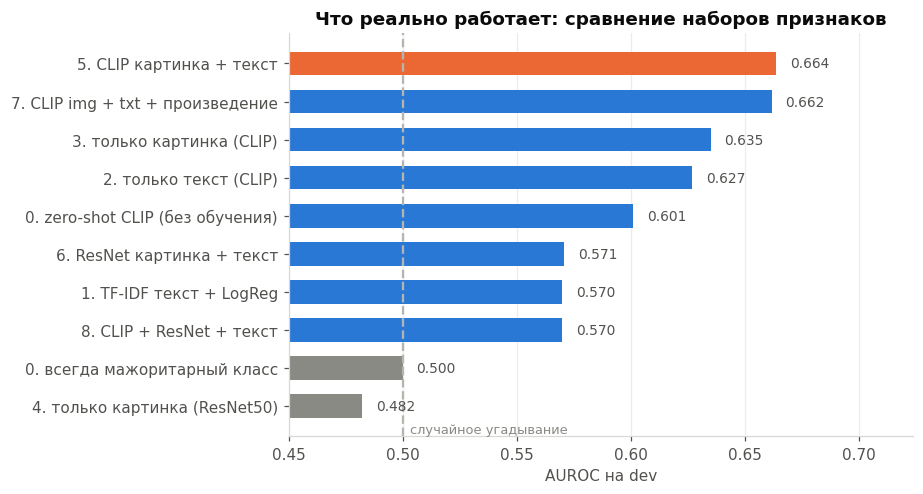

In [57]:
# главный график всего проекта: AUROC по экспериментам.
# горизонтальные бары, потому что подписи длинные; сортировка по значению,
# линия 0.5 - уровень случайного угадывания
plot_df = pd.DataFrame(RESULTS).set_index("эксперимент")["roc_auc"].sort_values()

fig, ax = plt.subplots(figsize=(8.5, 4.6))
colors = [C_GREY if v < 0.55 else C_BLUE for v in plot_df.values]
colors[-1] = C_ORANGE          # лучший результат выделяю
bars = ax.barh(plot_df.index, plot_df.values, color=colors, height=0.62)

for y, v in zip(range(len(plot_df)), plot_df.values):
    ax.text(v + 0.006, y, f"{v:.3f}", va="center", fontsize=9, color="#52514e")

ax.axvline(0.5, color="#b5b5b0", linewidth=1.5, linestyle="--")
ax.text(0.503, -0.7, "случайное угадывание", fontsize=8.5, color="#8a8a85")
ax.set_xlim(0.45, max(plot_df.values) + 0.06)
ax.set_xlabel("AUROC на dev")
ax.set_title("Что реально работает: сравнение наборов признаков")
ax.grid(axis="y", visible=False)
tidy(ax)
plt.tight_layout()
plt.show()

---
## 8. Подбор модели

Лучший набор признаков зафиксировала - теперь подбираю к нему алгоритм и гиперпараметры.
Силу регуляризации `C` выбираю по кросс-валидации **на train**, а не по dev: если крутить
гиперпараметры прямо по dev, он перестаёт быть честной оценкой.

In [58]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# беру не «на глаз», а тот набор, который реально победил в таблице выше
_trained = [r for r in RESULTS if r.get("blocks")]
_best = max(_trained, key=lambda r: r["roc_auc"])
BEST_BLOCKS = _best["blocks"]
BEST_BLOCKS_NAME = _best["эксперимент"]
print(f"лучший набор признаков: {BEST_BLOCKS_NAME}  ->  {BEST_BLOCKS}\n")

X_train_best = build_features("train", BEST_BLOCKS)
X_dev_best = build_features("dev", BEST_BLOCKS)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid_rows = []
for C in [0.01, 0.1, 0.3, 1.0, 3.0, 10.0]:
    pipe = make_pipeline(StandardScaler(),
                         LogisticRegression(max_iter=3000, C=C, random_state=RANDOM_STATE))
    # n_jobs=1 специально: в параллельных воркерах не действует подавление
    # предупреждений и вывод забивается мусором от BLAS
    scores = cross_val_score(pipe, X_train_best, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
    grid_rows.append({"C": C, "cv_auc": scores.mean(), "cv_std": scores.std()})
    print(f"C={C:<6} CV AUROC = {scores.mean():.3f} ± {scores.std():.3f}")

grid_df = pd.DataFrame(grid_rows)
BEST_C = float(grid_df.loc[grid_df["cv_auc"].idxmax(), "C"])
print(f"\nвыбрала C = {BEST_C}")
print("CV-оценка на train выше, чем качество на dev, и это нормально:")
print("train перекошен по классам, а dev сбалансирован, то есть dev просто другой и сложнее.")
print("сравнивать между собой можно только числа внутри одного столбца.")

лучший набор признаков: 5. CLIP картинка + текст  ->  ['img_clip', 'txt_clip']

C=0.01   CV AUROC = 0.765 ± 0.009
C=0.1    CV AUROC = 0.755 ± 0.008
C=0.3    CV AUROC = 0.753 ± 0.007
C=1.0    CV AUROC = 0.753 ± 0.007
C=3.0    CV AUROC = 0.753 ± 0.006
C=10.0   CV AUROC = 0.752 ± 0.006

выбрала C = 0.01
CV-оценка на train выше, чем качество на dev, и это нормально:
train перекошен по классам, а dev сбалансирован, то есть dev просто другой и сложнее.
сравнивать между собой можно только числа внутри одного столбца.


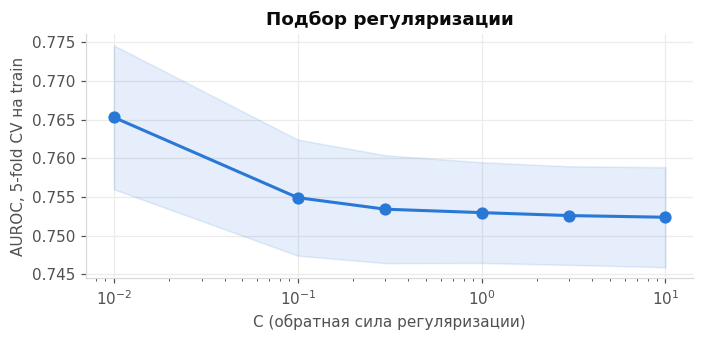

In [59]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(grid_df["C"], grid_df["cv_auc"], color=C_BLUE, linewidth=2, marker="o", markersize=7)
ax.fill_between(grid_df["C"], grid_df["cv_auc"] - grid_df["cv_std"],
                grid_df["cv_auc"] + grid_df["cv_std"], color=C_BLUE, alpha=0.12)
ax.set_xscale("log")
ax.set_xlabel("C (обратная сила регуляризации)")
ax.set_ylabel("AUROC, 5-fold CV на train")
ax.set_title("Подбор регуляризации")
tidy(ax)
plt.tight_layout()
plt.show()

In [60]:
# сравниваю разные алгоритмы на одном и том же наборе признаков.
# линейная модель на эмбеддингах обычно уже очень хороша, но проверить стоит
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

MODELS = {
    "LogReg (подобранная C)": LogisticRegression(max_iter=3000, C=BEST_C,
                                                 random_state=RANDOM_STATE),
    "Linear SVM (калиброванный)": CalibratedClassifierCV(
        LinearSVC(C=0.1, max_iter=5000, random_state=RANDOM_STATE), cv=3),
    "MLP 256": MLPClassifier(hidden_layer_sizes=(256,), max_iter=400,
                             early_stopping=True, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=400, n_jobs=-1,
                                            min_samples_leaf=2, random_state=RANDOM_STATE),
    "Градиентный бустинг": HistGradientBoostingClassifier(max_iter=250,
                                                          random_state=RANDOM_STATE),
}

model_rows = []
model_probs = {}
for name, clf in MODELS.items():
    pipe = make_pipeline(StandardScaler(), clf)
    t0 = time.time()
    pipe.fit(X_train_best, y_train)
    probs = pipe.predict_proba(X_dev_best)[:, 1]
    r = evaluate(y_dev, probs)
    r.update({"модель": name, "сек": round(time.time() - t0, 1)})
    model_rows.append(r)
    model_probs[name] = probs
    print(f"{name:28s} AUROC={r['roc_auc']:.3f}  acc={r['accuracy']:.3f}  "
          f"F1={r['f1']:.3f}  ({r['сек']} с)")

models_df = pd.DataFrame(model_rows).set_index("модель").round(3)
display(models_df.sort_values("roc_auc", ascending=False))

BEST_MODEL_NAME = models_df["roc_auc"].idxmax()
print(f"\nлучшая модель: {BEST_MODEL_NAME}")

LogReg (подобранная C)       AUROC=0.670  acc=0.592  F1=0.455  (0.2 с)
Linear SVM (калиброванный)   AUROC=0.656  acc=0.564  F1=0.374  (9.9 с)
MLP 256                      AUROC=0.698  acc=0.624  F1=0.508  (1.2 с)
Random Forest                AUROC=0.629  acc=0.534  F1=0.194  (13.1 с)
Градиентный бустинг          AUROC=0.684  acc=0.568  F1=0.372  (7.5 с)


,accuracy,roc_auc,f1,сек
модель,,,,
MLP 256,0.624,0.698,0.508,1.2
Градиентный бустинг,0.568,0.684,0.372,7.5
LogReg (подобранная C),0.592,0.670,0.455,0.2
Linear SVM (калиброванный),0.564,0.656,0.374,9.9
Random Forest,0.534,0.629,0.194,13.1



лучшая модель: MLP 256


---
## 9. Оценка лучшей модели

Смотрю на неё подробно: ROC-кривые в сравнении с бейзлайнами, матрица ошибок,
полный отчёт по классам и подбор порога решения.

Порог 0.5 тут заведомо не оптимален: модель обучалась на перекошенном `train` (36% hateful),
а применяется к сбалансированному `dev` (50%), поэтому по умолчанию она систематически
недооценивает класс hateful. Порог подбираю по **macro-F1** - он одинаково взвешивает оба
класса. Если максимизировать F1 только положительного класса, оптимум уезжает почти в ноль:
модель начинает называть hateful почти всё подряд, F1 растёт, а пользы от такой модели нет.

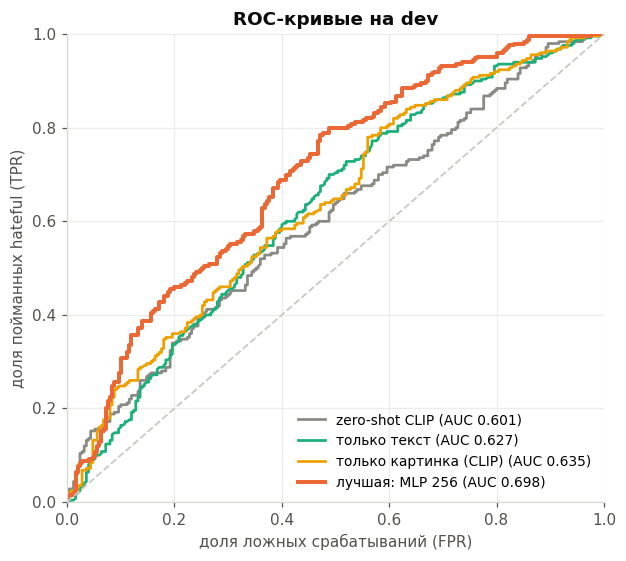

In [61]:
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix, classification_report

best_probs = model_probs[BEST_MODEL_NAME]

curves = [
    ("zero-shot CLIP", zero_shot_dev_probs, C_GREY),
    ("только текст", p_txt, C_AQUA),
    ("только картинка (CLIP)", p_imgclip, C_YELLOW),
    (f"лучшая: {BEST_MODEL_NAME}", best_probs, C_ORANGE),
]

fig, ax = plt.subplots(figsize=(5.8, 5.2))
for label, probs, color in curves:
    fpr, tpr, _ = roc_curve(y_dev, probs)
    auc = roc_auc_score(y_dev, probs)
    lw = 2.6 if color == C_ORANGE else 1.8
    ax.plot(fpr, tpr, color=color, linewidth=lw, label=f"{label} (AUC {auc:.3f})")

ax.plot([0, 1], [0, 1], color="#c9c9c4", linewidth=1.2, linestyle="--")
ax.set_xlabel("доля ложных срабатываний (FPR)")
ax.set_ylabel("доля пойманных hateful (TPR)")
ax.set_title("ROC-кривые на dev")
ax.legend(loc="lower right", fontsize=9)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
tidy(ax)
plt.tight_layout()
plt.show()

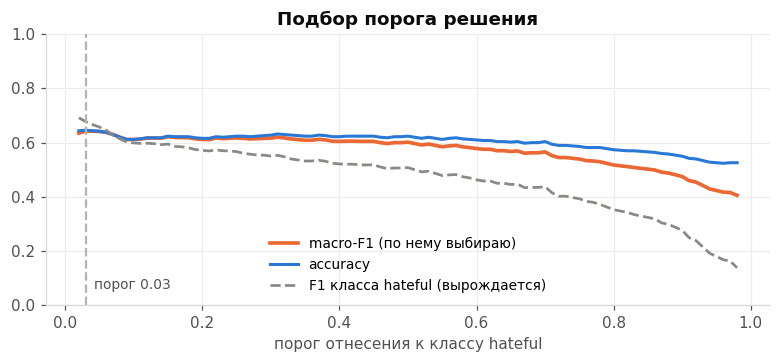

порог 0.50: macro-F1 0.602  accuracy 0.624  доля предсказанных hateful 26.4%
порог 0.03: macro-F1 0.643  accuracy 0.646  доля предсказанных hateful 59.8%


In [62]:
# три кривые в зависимости от порога. выбираю по macro-F1: он не даёт
# выродиться в "назову всё hateful", в отличие от F1 одного класса
thresholds = np.linspace(0.02, 0.98, 97)
macro_f1s = [f1_score(y_dev, (best_probs >= t).astype(int),
                      average="macro", zero_division=0) for t in thresholds]
pos_f1s = [f1_score(y_dev, (best_probs >= t).astype(int), zero_division=0) for t in thresholds]
accs = [accuracy_score(y_dev, (best_probs >= t).astype(int)) for t in thresholds]

BEST_THRESHOLD = float(thresholds[int(np.argmax(macro_f1s))])

fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.plot(thresholds, macro_f1s, color=C_ORANGE, linewidth=2.4, label="macro-F1 (по нему выбираю)")
ax.plot(thresholds, accs, color=C_BLUE, linewidth=2, label="accuracy")
ax.plot(thresholds, pos_f1s, color=C_GREY, linewidth=1.8, linestyle="--",
        label="F1 класса hateful (вырождается)")
ax.axvline(BEST_THRESHOLD, color="#b5b5b0", linestyle="--", linewidth=1.5)
ax.text(BEST_THRESHOLD + 0.012, 0.06, f"порог {BEST_THRESHOLD:.2f}", fontsize=9, color="#52514e")
ax.set_xlabel("порог отнесения к классу hateful")
ax.set_ylim(0, 1)
ax.set_title("Подбор порога решения")
ax.legend(fontsize=9, loc="lower center")
tidy(ax)
plt.tight_layout()
plt.show()

for t in [0.5, BEST_THRESHOLD]:
    p = (best_probs >= t).astype(int)
    print(f"порог {t:.2f}: macro-F1 {f1_score(y_dev, p, average='macro', zero_division=0):.3f}  "
          f"accuracy {accuracy_score(y_dev, p):.3f}  "
          f"доля предсказанных hateful {p.mean():.1%}")

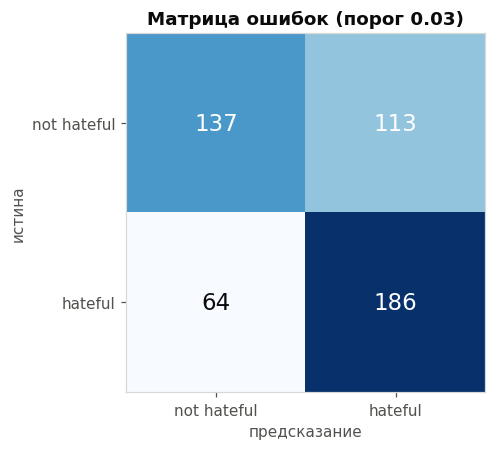

              precision    recall  f1-score   support

 not hateful      0.682     0.548     0.608       250
     hateful      0.622     0.744     0.678       250

    accuracy                          0.646       500
   macro avg      0.652     0.646     0.643       500
weighted avg      0.652     0.646     0.643       500



In [63]:
preds = (best_probs >= BEST_THRESHOLD).astype(int)
cm = confusion_matrix(y_dev, preds)

fig, ax = plt.subplots(figsize=(4.6, 4.2))
im = ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=15,
                color="white" if cm[i, j] > cm.max() * 0.55 else "#0b0b0b")
ax.set_xticks([0, 1]); ax.set_xticklabels([CLASS_NAMES[0], CLASS_NAMES[1]])
ax.set_yticks([0, 1]); ax.set_yticklabels([CLASS_NAMES[0], CLASS_NAMES[1]])
ax.set_xlabel("предсказание"); ax.set_ylabel("истина")
ax.set_title(f"Матрица ошибок (порог {BEST_THRESHOLD:.2f})")
ax.grid(False)
plt.tight_layout()
plt.show()

print(classification_report(y_dev, preds, target_names=[CLASS_NAMES[0], CLASS_NAMES[1]],
                            digits=3))

---
## 10. Анализ ошибок

Смотрю глазами на примеры, где модель ошиблась сильнее всего. Это самая полезная часть:
она объясняет, чего подходу не хватает.

ложных срабатываний (безобидный назвала hateful): 113
пропусков (hateful назвала безобидным):           64


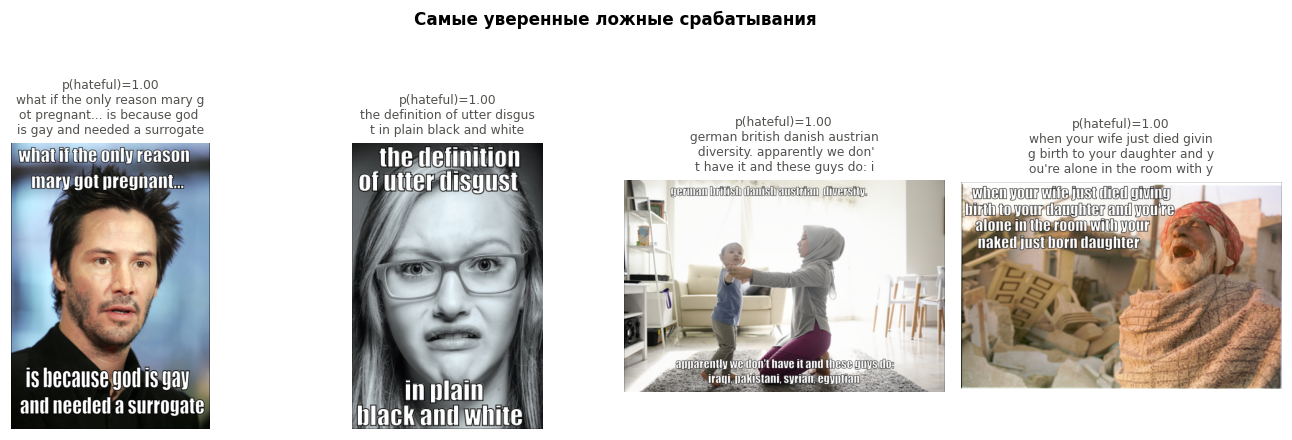

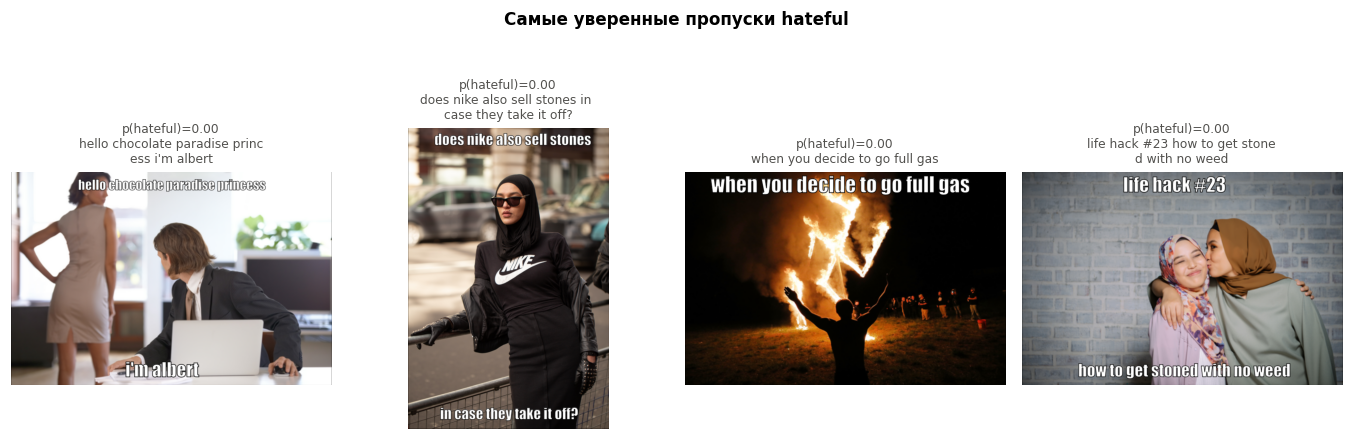

In [64]:
err = dev_df.copy()
err["prob"] = best_probs
err["pred"] = preds
err["ошибка"] = err["pred"] != err["label"].astype(int)

fp = err[(err["label"] == 0) & (err["pred"] == 1)].sort_values("prob", ascending=False)
fn = err[(err["label"] == 1) & (err["pred"] == 0)].sort_values("prob")

print(f"ложных срабатываний (безобидный назвала hateful): {len(fp)}")
print(f"пропусков (hateful назвала безобидным):           {len(fn)}")


def show_errors(sub, title, n=4):
    if len(sub) == 0:
        print("нет таких примеров")
        return
    sub = sub.head(n)
    fig, axes = plt.subplots(1, len(sub), figsize=(3.1 * len(sub), 3.8))
    for ax, (_, row) in zip(np.atleast_1d(axes), sub.iterrows()):
        ax.imshow(Image.open(row["img_path"]).convert("RGB"))
        ax.set_axis_off()
        txt = row["text"]
        wrapped = "\n".join([txt[i:i + 30] for i in range(0, min(len(txt), 90), 30)])
        ax.set_title(f"p(hateful)={row['prob']:.2f}\n{wrapped}", fontsize=8,
                     color="#52514e", fontweight="normal")
    fig.suptitle(title, fontsize=11, fontweight="bold", y=1.04)
    plt.tight_layout()
    plt.show()


show_errors(fp, "Самые уверенные ложные срабатывания")
show_errors(fn, "Самые уверенные пропуски hateful")

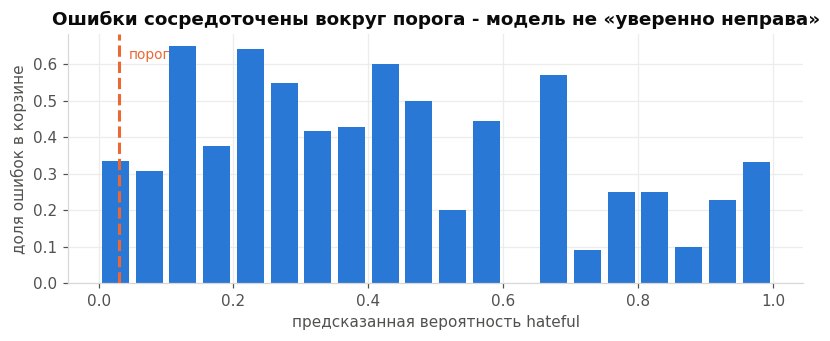

In [65]:
# где ошибки концентрируются по уверенности модели: если модель откалибрована,
# ошибок должно быть больше всего около порога
bins = np.linspace(0, 1, 21)
err["bin"] = pd.cut(err["prob"], bins, include_lowest=True)
rate = err.groupby("bin", observed=False)["ошибка"].agg(["mean", "size"])
rate = rate[rate["size"] >= 5]

fig, ax = plt.subplots(figsize=(7.5, 3.2))
centers = [iv.mid for iv in rate.index]
ax.bar(centers, rate["mean"], width=0.04, color=C_BLUE)
ax.axvline(BEST_THRESHOLD, color=C_ORANGE, linewidth=2, linestyle="--")
ax.text(BEST_THRESHOLD + 0.015, ax.get_ylim()[1] * 0.9, "порог", color=C_ORANGE, fontsize=9)
ax.set_xlabel("предсказанная вероятность hateful")
ax.set_ylabel("доля ошибок в корзине")
ax.set_title("Ошибки сосредоточены вокруг порога - модель не «уверенно неправа»")
tidy(ax)
plt.tight_layout()
plt.show()

---
## 11. Предсказания на test

`test.jsonl` без лейблов, метрики там посчитать нельзя - это конкурсный сплит.
Поэтому обучаю финальную модель на `train + dev` (больше данных - лучше) и сохраняю
предсказания в CSV.

Одна тонкость, из-за которой легко ошибиться. Порог, подобранный в разделе 9,
относится к модели, обученной **только на train**. Финальная модель учится на другом наборе,
её вероятности откалиброваны иначе, и старый порог к ней просто не подходит - если его
применить, доля предсказанных hateful улетает далеко за разумную.
Поэтому порог для финальной модели подбираю заново, по **out-of-fold** предсказаниям на
`train + dev`: каждый пример получает предсказание от модели, которая его не видела.

In [66]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

X_full = np.vstack([build_features("train", BEST_BLOCKS), build_features("dev", BEST_BLOCKS)])
y_full = np.concatenate([y_train, y_dev])
X_test_best = build_features("test", BEST_BLOCKS)

final_model = make_pipeline(StandardScaler(), clone(MODELS[BEST_MODEL_NAME]))

# out-of-fold вероятности: честная оценка того, что модель выдаёт на невиданных данных
oof_probs = cross_val_predict(final_model, X_full, y_full, cv=cv,
                              method="predict_proba", n_jobs=1)[:, 1]
oof_grid = np.linspace(0.02, 0.98, 97)
oof_macro = [f1_score(y_full, (oof_probs >= t).astype(int), average="macro", zero_division=0)
             for t in oof_grid]
FINAL_THRESHOLD = float(oof_grid[int(np.argmax(oof_macro))])

print(f"out-of-fold AUROC на train+dev: {roc_auc_score(y_full, oof_probs):.3f}")
print(f"порог для финальной модели:     {FINAL_THRESHOLD:.2f} "
      f"(на dev-модели был {BEST_THRESHOLD:.2f})")
print()

final_model.fit(X_full, y_full)
test_probs = final_model.predict_proba(X_test_best)[:, 1]
test_preds = (test_probs >= FINAL_THRESHOLD).astype(int)

submission = pd.DataFrame({
    "id": test_df["id"],
    "proba": test_probs.round(5),
    "label": test_preds,
})
out_path = PROJECT_DIR / "submission.csv"
submission.to_csv(out_path, index=False)

print(f"обучила {BEST_MODEL_NAME} на {len(y_full)} примерах (train+dev)")
print(f"сохранила предсказания в {out_path}")
print(f"предсказано hateful на test: {test_preds.mean():.1%}")
print(f"для сравнения: в train+dev реальная доля {y_full.mean():.1%}")
display(submission.head())

out-of-fold AUROC на train+dev: 0.749
порог для финальной модели:     0.42 (на dev-модели был 0.03)

обучила MLP 256 на 9000 примерах (train+dev)
сохранила предсказания в /Users/amina/Desktop/proj/venv_bofs/capstone project/submission.csv
предсказано hateful на test: 33.1%
для сравнения: в train+dev реальная доля 36.7%


,id,proba,label
0,16395,0.55553,1
1,37405,0.74799,1
2,94180,0.73839,1
3,54321,0.10786,0
4,97015,0.99617,1


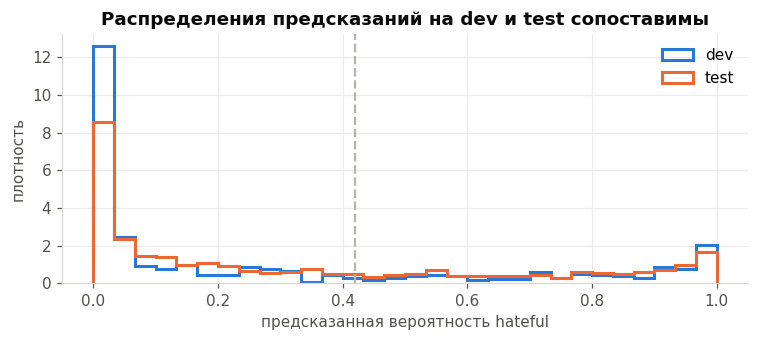

In [67]:
# на всякий случай смотрю на распределение вероятностей на тесте:
# если оно резко отличается от dev - что-то пошло не так
fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.linspace(0, 1, 31)
ax.hist(best_probs, bins=bins, histtype="step", linewidth=2, color=C_BLUE,
        density=True, label="dev")
ax.hist(test_probs, bins=bins, histtype="step", linewidth=2, color=C_ORANGE,
        density=True, label="test")
ax.axvline(FINAL_THRESHOLD, color="#b5b5b0", linestyle="--", linewidth=1.5)
ax.set_xlabel("предсказанная вероятность hateful")
ax.set_ylabel("плотность")
ax.set_title("Распределения предсказаний на dev и test сопоставимы")
ax.legend()
tidy(ax)
plt.tight_layout()
plt.show()

---
## 12. Выводы

In [68]:
final_table = (pd.DataFrame(RESULTS)
               .set_index("эксперимент")[["roc_auc", "accuracy", "f1"]]
               .sort_values("roc_auc", ascending=False)
               .round(3))
display(final_table)

print(f"лучший набор признаков:  {BEST_BLOCKS_NAME}")
print(f"лучший алгоритм:         {BEST_MODEL_NAME}")
print(f"порог решения:           {FINAL_THRESHOLD:.2f} (финальная модель)")
print(f"итог на dev:             AUROC {models_df.loc[BEST_MODEL_NAME, 'roc_auc']:.3f}, "
      f"accuracy {models_df.loc[BEST_MODEL_NAME, 'accuracy']:.3f}, "
      f"F1 {models_df.loc[BEST_MODEL_NAME, 'f1']:.3f}")
print(f"прирост над zero-shot:   +{models_df.loc[BEST_MODEL_NAME, 'roc_auc'] - ZERO_SHOT_AUC:.3f} AUROC")

,roc_auc,accuracy,f1
эксперимент,,,
5. CLIP картинка + текст,0.664,0.588,0.458
7. CLIP img + txt + произведение,0.662,0.576,0.462
3. только картинка (CLIP),0.635,0.578,0.460
2. только текст (CLIP),0.627,0.552,0.349
0. zero-shot CLIP (без обучения),0.601,0.580,0.553
6. ResNet картинка + текст,0.571,0.548,0.449
1. TF-IDF текст + LogReg,0.570,0.518,0.254
8. CLIP + ResNet + текст,0.570,0.538,0.464
0. всегда мажоритарный класс,0.500,0.500,0.000


лучший набор признаков:  5. CLIP картинка + текст
лучший алгоритм:         MLP 256
порог решения:           0.42 (финальная модель)
итог на dev:             AUROC 0.698, accuracy 0.624, F1 0.508
прирост над zero-shot:   +0.097 AUROC


### Что получилось

1. **Zero-shot CLIP решает задачу еле-еле.** Он ощутимо лучше монетки, но до обученной
   модели не дотягивает, и качество заметно зависит от формулировки промпта. То есть
   «спросить у CLIP словами» - не решение, и весь прирост сверху это вклад обучения.
2. **Обучение поверх замороженных эмбеддингов даёт прирост** - и это главный практический
   результат: предобученные признаки плюс лёгкий классификатор работают, дообучать
   всю сеть не обязательно.
3. **CLIP как image-энкодер сильнее ResNet50**, хотя его вектор вчетверо короче.
   ResNet-признаки на этой задаче местами проваливаются даже ниже случайного уровня -
   ImageNet-объекты просто не та информация, которая отличает hateful мем от обычного.
4. **Текст сам по себе тоже мало что даёт.** TF-IDF по словам почти не работает, то есть
   задача не сводится к списку «плохих слов» - иначе бы её решал обычный текстовый фильтр.
5. **Объединение модальностей лучше любой одиночной**, но прирост скромный. Конкатенация
   позволяет линейной модели взвесить оба источника, но не умеет их «перемножать» - поэтому
   я и пробовала отдельный блок поэлементного произведения.
6. **Потолок подхода виден в анализе ошибок.** Модель ошибается там, где смысл возникает
   из совмещения безобидной картинки с безобидным текстом. Замороженные эмбеддинги кодируют
   картинку и текст по отдельности, а ключ - именно в их взаимодействии.
7. **Абсолютные числа честно невысокие.** Это ожидаемо: датасет специально собран так, чтобы
   односторонние модели на нём ломались, и в оригинальной статье простые мультимодальные
   бейзлайны тоже далеки от человека.

### Что делать дальше

- Взять модель, которая изначально обрабатывает картинку и текст **вместе** (VisualBERT,
  ViLT, LLaVA) вместо склейки двух отдельных векторов.
- Распознать текст прямо с картинки (OCR): сейчас текст берётся из разметки, а часть
  смысла остаётся в надписи на изображении.
- Дообучить (fine-tune) верхние слои CLIP на этой задаче вместо полной заморозки.
- Добавить аугментации и больше данных - 8 500 примеров для такой тонкой задачи мало.

### Ограничения

- Метрики посчитаны на `dev` из 500 примеров, доверительный интервал у AUROC тут заметный
  (порядка ±0.04), так что различия в третьем знаке между моделями ничего не значат.
- `train` и `dev` по-разному сбалансированы, поэтому CV-оценка на train и оценка на dev
  не сравнимы напрямую.
- На `test` лейблов нет, так что итоговое качество на нём проверить нельзя - только отправить
  предсказания в конкурс.
- Порог решения и выбор алгоритма делались по `dev`, то есть под него слегка подогнаны.